# Assignment 07: A First Machine Learning SDM

## BIO597 Spatial Analysis of Biodiversity

Repeat the workflow from Lab 07 for a Maine amphibian species of your choice. Focus on understanding what the model learns and what its predictions mean. You may reuse code from the lab.

## Deliverable

Submit this notebook with your completed code, figures, and short written answers, plus a saved suitability raster. There is no need to tune model settings or compare additional algorithms.


## 1. Import packages and load the data

Run this notebook from `docs/assignments`. Import the packages used in Lab 07. Load the two supplied files and display species counts.


In [ ]:
pip install rioxarray

In [ ]:
pip install scikit-learn

In [1]:
# Import the packages used in Lab 07.
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray
import xarray as xr

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

In [7]:


amphibians = gpd.read_file("../data/amphibians+bioclim.geojson")
climate = xr.open_dataset("../data/maine_bioclim.nc")

# Display species counts.
amphibians["species"].value_counts().head(25)


,gbifID,species,decimalLongitude,decimalLatitude,coordinateUncertaintyInMeters,year,bio_1,bio_10,bio_11,bio_2,...,bio_6,bio_4,bio_15,bio_14,bio_5,bio_8,bio_19,bio_18,bio_9,geometry
0,6520738729,Lithobates catesbeianus,-68.660278,44.902551,5.0,2026.0,6.609500,18.934000,-6.425333,11.662333,...,-13.808,1018.586365,9.000063,68.0,26.820,1.970667,249.0,266.0,-0.546000,POINT (-68.66028 44.90255)
1,6520735611,Aquarana clamitans,-69.649014,44.735713,10.0,2026.0,6.332833,18.769333,-6.940667,12.243667,...,-14.944,1034.367798,12.902308,65.0,26.612,1.783333,229.0,277.0,-5.721334,POINT (-69.64901 44.73571)
2,6520721493,Lithobates palustris,-68.636788,44.860466,112.0,2022.0,6.544000,18.765999,-6.392000,11.580667,...,-13.752,1010.674011,8.947875,70.0,26.608,1.951333,255.0,263.0,-5.095333,POINT (-68.63679 44.86047)
3,6520700408,Lithobates palustris,-69.865662,44.361917,4.0,2026.0,6.777333,18.994667,-6.078000,11.249333,...,-13.428,1008.412781,9.855001,71.0,26.364,2.227333,252.0,270.0,-4.852000,POINT (-69.86566 44.36192)
4,6520670325,Boreorana sylvatica,-70.411203,43.454942,4.0,2025.0,7.865667,18.892000,-3.424000,10.690000,...,-10.080,900.472961,13.864340,80.0,25.896,3.824667,287.0,244.0,18.892000,POINT (-70.4112 43.45494)


## 2. Choose your species

Choose a common species other than the wood frog, with at least 500 records. Keep records with coordinate uncertainty below 100 m, as in the lab.


Number of records: 657


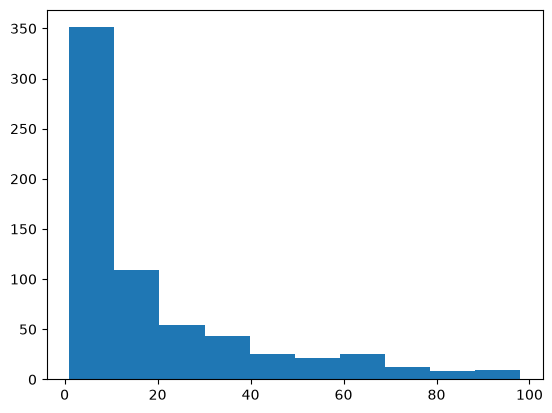

In [8]:
target_species = "Dryophytes versicolor"

# Select your species and apply the uncertainty filter.
# Store the result as presence and print its record count.

presence = amphibians[amphibians["species"] == target_species].copy()
presence = presence[presence["coordinateUncertaintyInMeters"] < 100].copy()

print("Number of records:", len(presence))


# Inspect the distribution of coordinate uncertainty
_ = plt.hist(presence["coordinateUncertaintyInMeters"])

**Why did you choose this species?** Write one or two sentences.

I chose this species because it has more than 500 records and I don't think I have used this species for previous assignments.

## 3. Keep all climate variables available

As in Lab 07, make a list called `climate_variables` containing `bio_1` through `bio_19`. We will choose the model predictors after preparing the modeling table.


In [10]:
# Create climate_variables and display these columns at your species' records.

climate_variables = ["bio_" + str(number) for number in range(1, 20)]

presence[climate_variables].head()


,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
13,8.071000,11.260000,30.350405,922.830444,26.840000,-10.260,37.099998,3.802000,19.408667,19.408667,-3.490667,1144.0,124.0,82.0,13.125590,335.0,252.0,252.0,281.0
41,7.176833,10.757667,28.090836,977.089783,26.152000,-12.144,38.296001,2.706667,18.220667,19.052000,-5.226000,1143.0,114.0,81.0,11.788889,325.0,249.0,256.0,284.0
52,7.481333,10.960000,29.006987,953.498962,26.080000,-11.704,37.784000,3.174667,18.316000,19.039999,-4.619333,1162.0,120.0,82.0,12.964702,337.0,251.0,252.0,291.0
59,7.567667,10.810667,28.886988,948.200500,26.064001,-11.360,37.424000,3.270667,19.081333,19.081333,-4.444667,1154.0,119.0,81.0,13.038893,335.0,249.0,249.0,290.0
75,7.481333,10.960000,29.006987,953.498962,26.080000,-11.704,37.784000,3.174667,18.316000,19.039999,-4.619333,1162.0,120.0,82.0,12.964702,337.0,251.0,252.0,291.0


## 4. Prepare presence and background tables

Use the prepared climate values at the occurrence records directly, as in the revised lab. We do not need to match records to raster cells or join tables by coordinates.

The code below prepares the climate grid for background sampling and mapping. Each grid row is a cell, but each presence row is an occurrence record. Several presence records may therefore describe the same climate cell.


In [12]:
grid = climate[climate_variables].to_dataframe().reset_index()
grid = grid[["x", "y"] + climate_variables]
grid = grid.dropna(subset=climate_variables)
grid.head()


,x,y,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,...,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
146,-69.229167,47.437500,2.610167,10.487667,24.623560,1133.966675,23.148001,-19.444000,42.592003,16.066000,...,16.066000,-12.065333,1093.0,110.0,67.0,13.786905,317.0,227.0,317.0,231.0
147,-69.187500,47.437500,2.620167,10.551667,24.738974,1134.299316,23.200001,-19.452000,42.652000,16.072001,...,16.072001,-12.078667,1080.0,110.0,66.0,14.227962,316.0,223.0,316.0,228.0
148,-69.145833,47.437500,2.786333,10.607333,24.855499,1130.561035,23.344000,-19.332001,42.676003,16.170000,...,16.170000,-11.888667,1043.0,108.0,63.0,14.921009,307.0,211.0,307.0,222.0
246,-69.270833,47.395833,2.161333,10.447333,24.595850,1134.809448,22.668001,-19.808001,42.476002,15.676667,...,15.676667,-12.473333,1130.0,116.0,69.0,14.441315,332.0,233.0,332.0,237.0
247,-69.229167,47.395833,2.441500,10.566333,24.831577,1130.958252,22.968000,-19.584000,42.552002,15.872000,...,15.872000,-12.190666,1099.0,113.0,67.0,14.589335,323.0,226.0,323.0,231.0


In [13]:
# Keep the prepared predictors and remove records with missing climate values.
presence_data = presence[climate_variables].dropna().copy()
presence_data["observed"] = 1

print("Usable presence records:", len(presence_data))
presence_data.head()


Usable presence records: 657


,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19,observed
13,8.071000,11.260000,30.350405,922.830444,26.840000,-10.260,37.099998,3.802000,19.408667,19.408667,-3.490667,1144.0,124.0,82.0,13.125590,335.0,252.0,252.0,281.0,1
41,7.176833,10.757667,28.090836,977.089783,26.152000,-12.144,38.296001,2.706667,18.220667,19.052000,-5.226000,1143.0,114.0,81.0,11.788889,325.0,249.0,256.0,284.0,1
52,7.481333,10.960000,29.006987,953.498962,26.080000,-11.704,37.784000,3.174667,18.316000,19.039999,-4.619333,1162.0,120.0,82.0,12.964702,337.0,251.0,252.0,291.0,1
59,7.567667,10.810667,28.886988,948.200500,26.064001,-11.360,37.424000,3.270667,19.081333,19.081333,-4.444667,1154.0,119.0,81.0,13.038893,335.0,249.0,249.0,290.0,1
75,7.481333,10.960000,29.006987,953.498962,26.080000,-11.704,37.784000,3.174667,18.316000,19.039999,-4.619333,1162.0,120.0,82.0,12.964702,337.0,251.0,252.0,291.0,1


In [14]:
# Sample available environments, using one background row per presence record.
background = grid.sample(n=len(presence_data), random_state=597).copy()
background["observed"] = 0

model_data = pd.concat([presence_data, background], ignore_index=True)
model_data["observed"].value_counts()


observed
1    657
0    657
Name: count, dtype: int64

The missing-value cleanup keeps incomplete presence records out of both models. `random_state=597` makes the background sample repeatable. Background is sampled from the full valid grid, so it can include cells where the species has been recorded. It represents available environments, not confirmed absences.

## 5. Define predictors and response

Start with `features = ["bio_1"]`, annual mean temperature, to connect with last week's model. Set `X` to this predictor column and `y` to the `observed` labels. Only the selected climate columns belong in `X`; the background's coordinate columns are for mapping.


In [17]:
model_data.head()

,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,...,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19,observed,x,y
0,8.071000,11.260000,30.350405,922.830444,26.840000,-10.260,37.099998,3.802000,19.408667,19.408667,...,124.0,82.0,13.125590,335.0,252.0,252.0,281.0,1,NaN,NaN
1,7.176833,10.757667,28.090836,977.089783,26.152000,-12.144,38.296001,2.706667,18.220667,19.052000,...,114.0,81.0,11.788889,325.0,249.0,256.0,284.0,1,NaN,NaN
2,7.481333,10.960000,29.006987,953.498962,26.080000,-11.704,37.784000,3.174667,18.316000,19.039999,...,120.0,82.0,12.964702,337.0,251.0,252.0,291.0,1,NaN,NaN
3,7.567667,10.810667,28.886988,948.200500,26.064001,-11.360,37.424000,3.270667,19.081333,19.081333,...,119.0,81.0,13.038893,335.0,249.0,249.0,290.0,1,NaN,NaN
4,7.481333,10.960000,29.006987,953.498962,26.080000,-11.704,37.784000,3.174667,18.316000,19.039999,...,120.0,82.0,12.964702,337.0,251.0,252.0,291.0,1,NaN,NaN


In [18]:
# Set features to bio_1 only.
features = ["bio_1"]

# Define X and y, following Lab 07.
X = model_data[features]
y = model_data["observed"]

print(X.head())
# print(y.head())


      bio_1
0  8.071000
1  7.176833
2  7.481333
3  7.567667
4  7.481333


## 6. Split, fit, and predict

Split `model_data` into `train_data` (75%) and `test_data` (25%) with `random_state=597``, as in the lab

Fit a `RandomForestRegressor` using only `bio_1`, with 100 trees, `min_samples_leaf=5`, and `random_state=597`.


In [20]:
# Split model_data into train_data and test_data.
# Define X_train, X_test, y_train, and y_test using features and observed.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

print("Training cells:", len(X_train))
print("Test cells:", len(X_test))

# Create model and fit it to the training data.
model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=597,
)
model.fit(X_train, y_train)

# Predict suitability for X_test.
test_prediction = model.predict(X_test)

Training cells: 985
Test cells: 329


## 7. Check the BIO1-only predictions

Calculate mean absolute error and store it as `bio1_error`. Plot test predictions for presence and background cells in overlapping histograms, as in the lab.


BIO1-only MAE: 0.294


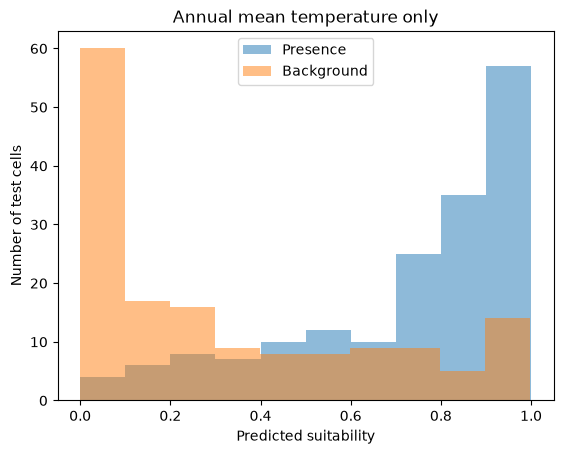

In [21]:
# Calculate and print bio1_error.
bio1_error = mean_absolute_error(y_test, test_prediction)
print("BIO1-only MAE:", round(bio1_error, 3))

# Plot the predicted score distributions for the two test labels.
plt.hist(test_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(test_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.title("Annual mean temperature only")
plt.legend()
plt.show()


**Interpretation:** Do test presence cells generally receive higher scores? Why should we use withheld cells to check the model?

Presence cells are generally receiving higher predicted suitability scores. It's important to use witheld cells to check how the model performs against unseen data. 
## 8. Add precipitation and compare MAE

Choose three new bioclim variables to test (you can look up the meanings of the variables
in the [bioclimatic variables documentation](https://www.worldclim.org/data/bioclim.html))

Change `features` to `["bio_X", "bio_XX", "bio_XX"]` (replacing the "X" values with the integer
index of the bioclim variables you chose). Create a new feature table (`X`) selecting just the features of interest and perform a new test/train split. Fit a new forest with these three predictors and calculate `three_variable_error`. Print both MAEs together.


In [22]:
# Select the three predictor columns from the existing training and test tables.
features = ["bio_5", "bio_6", "bio_12"]

# Fit three_variable_model and predict the same withheld cells.
X = model_data[features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

three_variable_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)
three_variable_model.fit(X_train, y_train)
three_variable_prediction = three_variable_model.predict(X_test)

# Calculate three_variable_error and print it beside bio1_error.
three_variable_error = mean_absolute_error(y_test, three_variable_prediction)

print("BIO1-only MAE:", round(bio1_error, 3))
print("BIO5 + BIO6 + BIO12 MAE:", round(three_variable_error, 3))


BIO1-only MAE: 0.294
BIO5 + BIO6 + BIO12 MAE: 0.274


**Interpretation:** Did the three new bioclim variables improve prediction error for your species? Explain why the new conditions you chose may or may not be relevant biologically.

Prediction error was reduced with the three new bioclim variables (max temp of warmest month, min temp of coldest month, and annual precipitation). The new conditions may be relevant to this species if the species is influened by timing and range of temperature change but I think annual precipitation is likely overgeneralized and less relevant (predictive) than seasonal precipitation would be. 

## 9. Make a suitability map

Fit a new `final_model` using all modeling rows and the three predictors. Predict scores for `grid[features]`. Use the plotting recipe from Lab 07 to turn the suitability column into a raster and map it from 0 to 1.


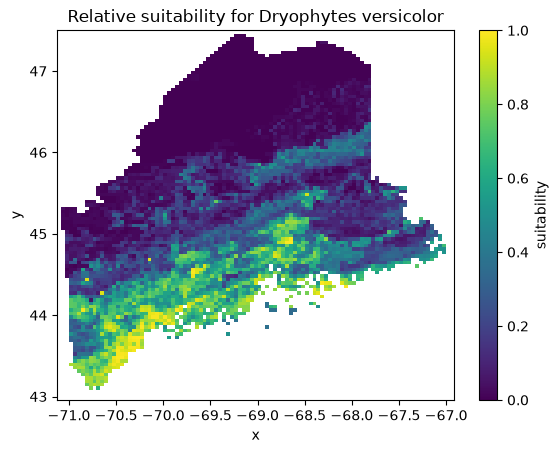

In [23]:
# Update X to include all three predictors.
X = model_data[features]

# Fit final_model with the same forest settings.
final_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)
final_model.fit(X, y)

# Add grid["suitability"], convert it to a raster named suitability, and plot it.
grid["suitability"] = final_model.predict(grid[features])
suitability = grid.set_index(["y", "x"])["suitability"].to_xarray()
suitability = suitability.reindex(y=climate.y, x=climate.x)

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Relative suitability for {target_species}")
plt.show()


**Interpretation:** Which parts of Maine receive high scores? Why should we describe these as relative suitability rather than probability of occurrence?

Southern Maine received high predicted suitability scores. This exercise predicts relative suitability rather than probability of occurrence because we lack absence data to actually predict occurrence. 


## 10. Plot variable importance

Use `final_model.feature_importances_` and `pd.Series()` as in the lab to make a bar plot for the three predictors.


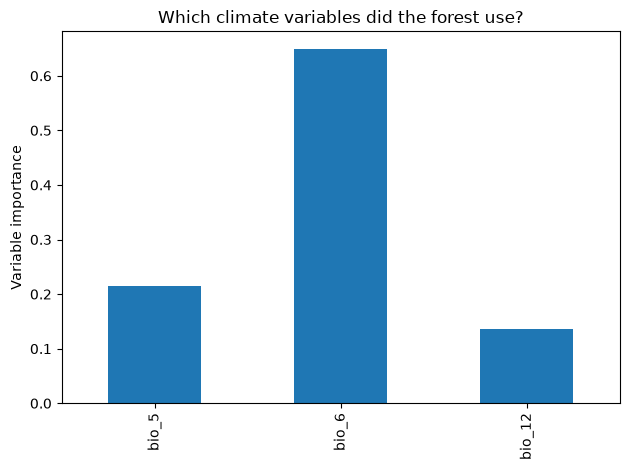

In [24]:
# Make and label a variable-importance plot.
importance = pd.Series(final_model.feature_importances_, index=features)
importance.plot.bar()
plt.ylabel("Variable importance")
plt.title("Which climate variables did the forest use?")
plt.tight_layout()
plt.show()



**Interpretation:** Which variable did your forest use most? Give one reason why this does not establish an ecological cause.

The forest used BIO6 (minimum temperature of the coldest month) the most. This means that the variable is predictive of occurrence but doesn't establish causation of occurrence - we don't know that spatial variance in this variable is the reason for species presence where it was recorded. 

## 11. Save your map

Save `suitability` as `Assignment07_suitability.tif` using the same CRS and export commands as the lab.


In [25]:
# Assign EPSG:4326 and save the suitability raster.
suitability = suitability.rio.write_crs("EPSG:4326")
suitability.rio.to_raster("Assignment07_suitability.tif")


## 12. Run the training and prediction again including all 19 bioclim variables

**Think about:** Do you predict that more variables will improve the MAE of the model?

In [26]:
# Run the full analysis again but this time include all 19 bioclim variables
features = ["bio_" + str(number) for number in range(1, 20)]

X = model_data[features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

all_variable_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=2,
)
all_variable_model.fit(X_train, y_train)
all_variable_prediction = all_variable_model.predict(X_test)
all_variable_error = mean_absolute_error(y_test, all_variable_prediction)

print("BIO1-only MAE:", round(bio1_error, 3))
print("BIO1 + BIO12 + BIO15 MAE:", round(three_variable_error, 3))
print("All variable MAE:", round(all_variable_error, 3))


BIO1-only MAE: 0.294
BIO1 + BIO12 + BIO15 MAE: 0.274
All variable MAE: 0.267


## Final reflection

Answer in two or three sentences per question.

1. How does this week's BIO1-only random forest differ from last week's hand-built temperature curve?

The hand-built temperature curve showed places in space that had similar temperature values as the places in space where species occurrences were recorded, and used similarity/dissimilarity to mean temperature values coinciding with species occurrence to rank all temperature values in the area of interest (state of Maine). This worked on the assumption that highest suitability coincided with the mean temperature at occurrence records. The temperature random forest model iteratively learned it's own temperature thresholds for predicting occurrence, with the potential to interpret multimodel/non-normal distributions of occurence records across temperatures rather than using the mean. 


2. What did the comparison with three predictors teach you? Would you expect more predictors always to reduce test error?

Using three predictors did decrease the mean absolute error, and I would expect more predictors (as long as they were biologically relevant) to reduce test error up to a point but lacking increased predictive power as correlation among variables increased. 

3. Several presence records can share a climate cell. Why might a random split then make prediction look easier than predicting a new location?

The randomly split occurrence records might put some of the presence records from a single climate cell into the training data and some into the testing data. Then, when the model runs into the test record from a cell that it already used to train on, it 

4. Name one habitat variable or sampling issue missing from your model. How might it affect the map?

I would expect vegetation cover or soil texture/soil moisture to increase predictive power and granularity of the map. 

## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, written answers, both MAEs, and saved raster. Commit and push the notebook and raster to your class GitHub repository.

```bash
git add docs/assignments/Assignment-07-MachineLearningSDM.ipynb docs/assignments/Assignment07_suitability.tif
git commit -m "Complete machine learning SDM assignment"
git push
```
